# House Price EDA 



In [1]:
from pathlib import Path
import sys
root = Path.cwd()
if not (root / 'src').exists():
    root = root.parent
sys.path.insert(0, str(root))
from src.data.week2_inputs import install_data_guard
install_data_guard()
from src.data.eda import run_eda
summary = run_eda()
print('Train rows:', summary['rows'])
print('Target median:', summary['target_median'])

Train rows: 1022
Target median: 165000.0


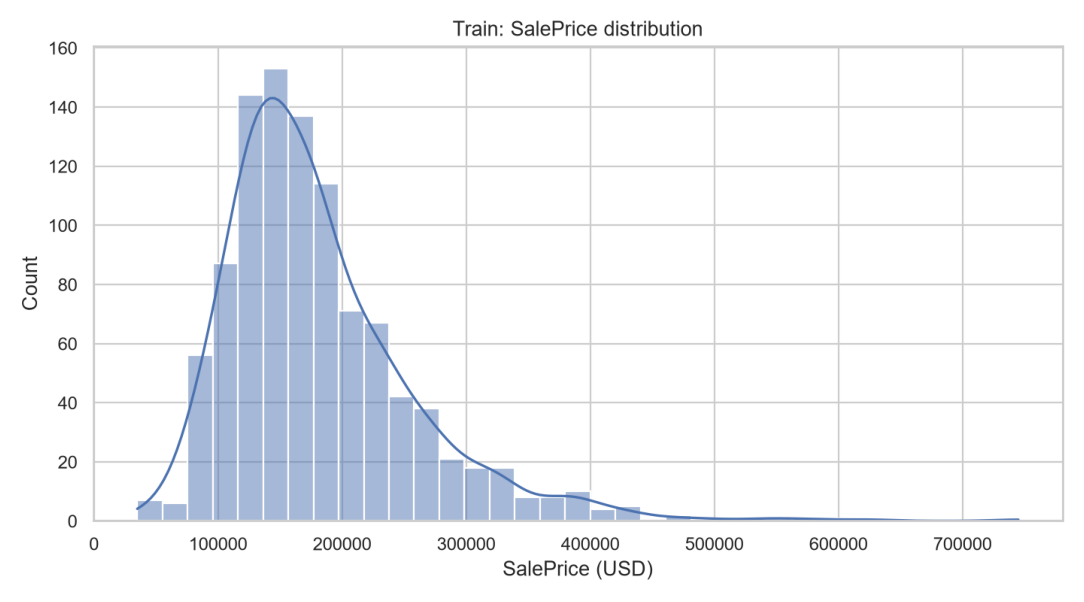

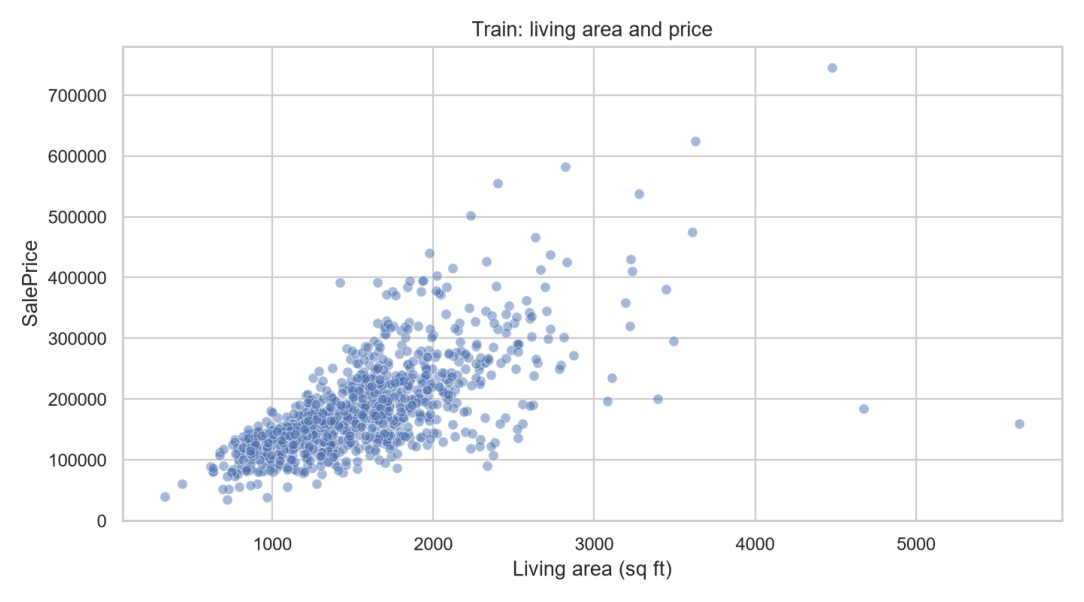

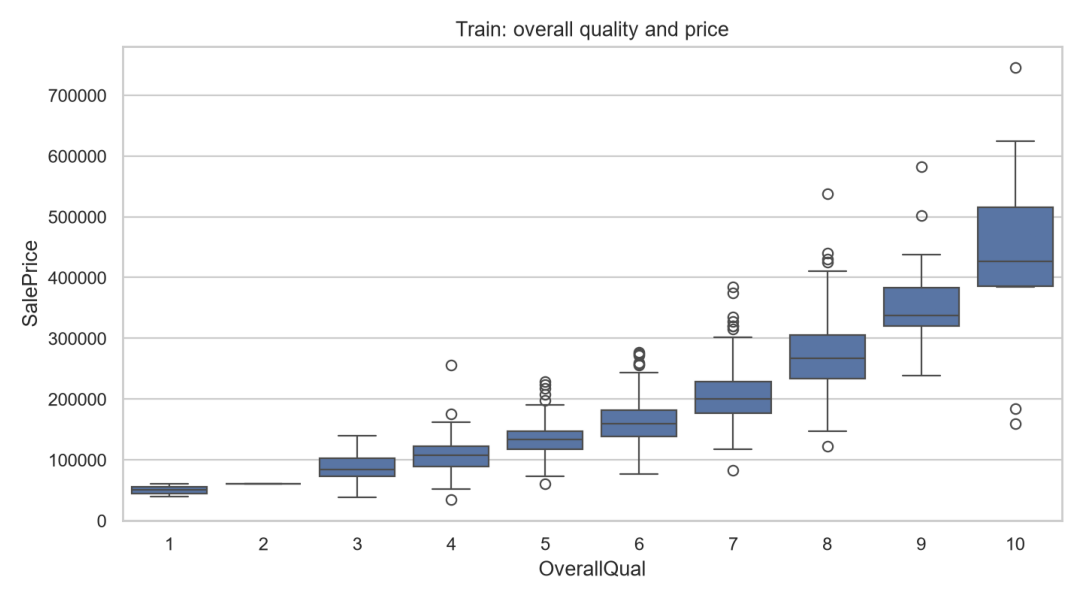

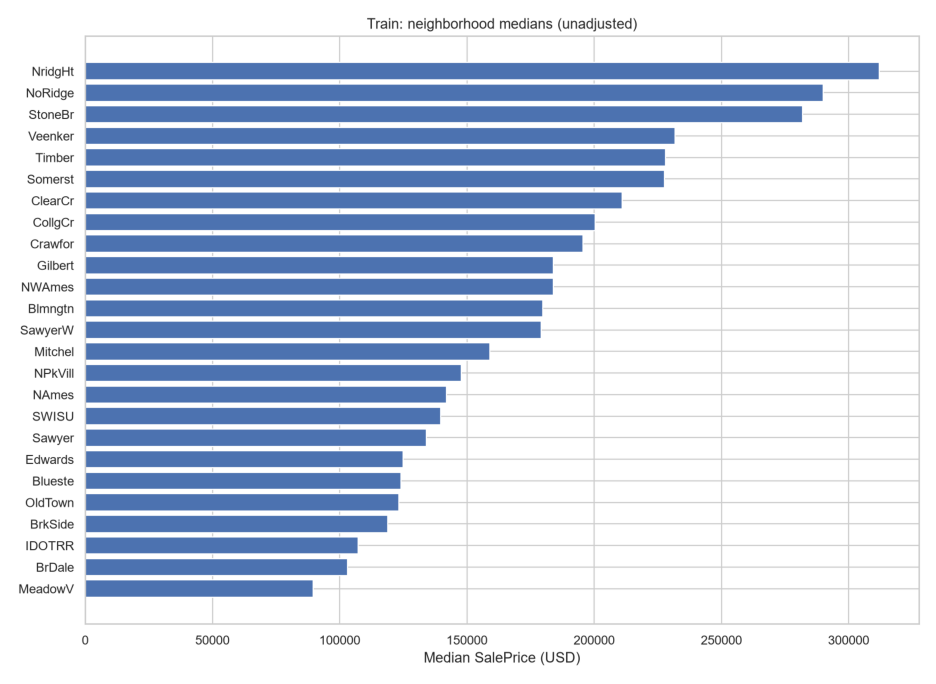

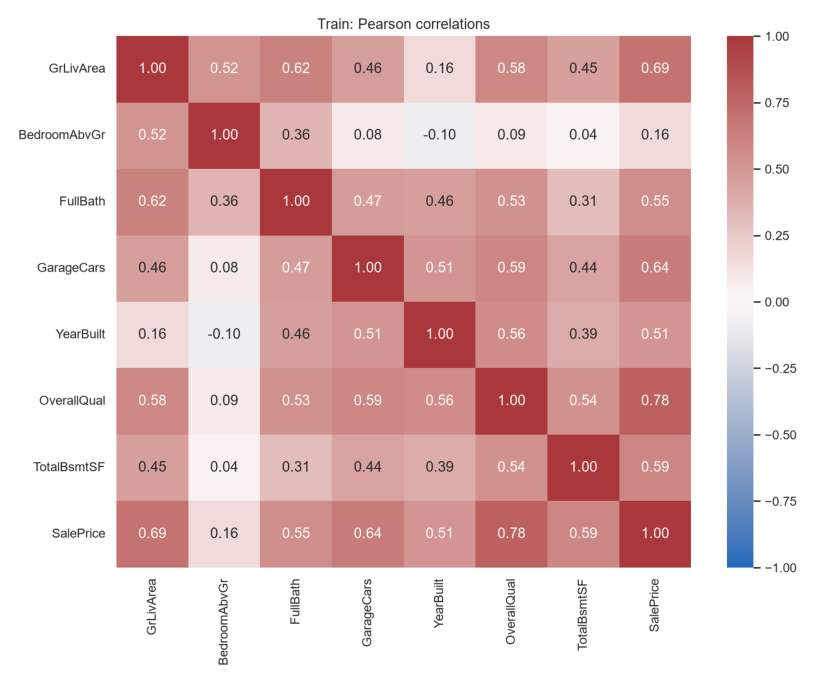

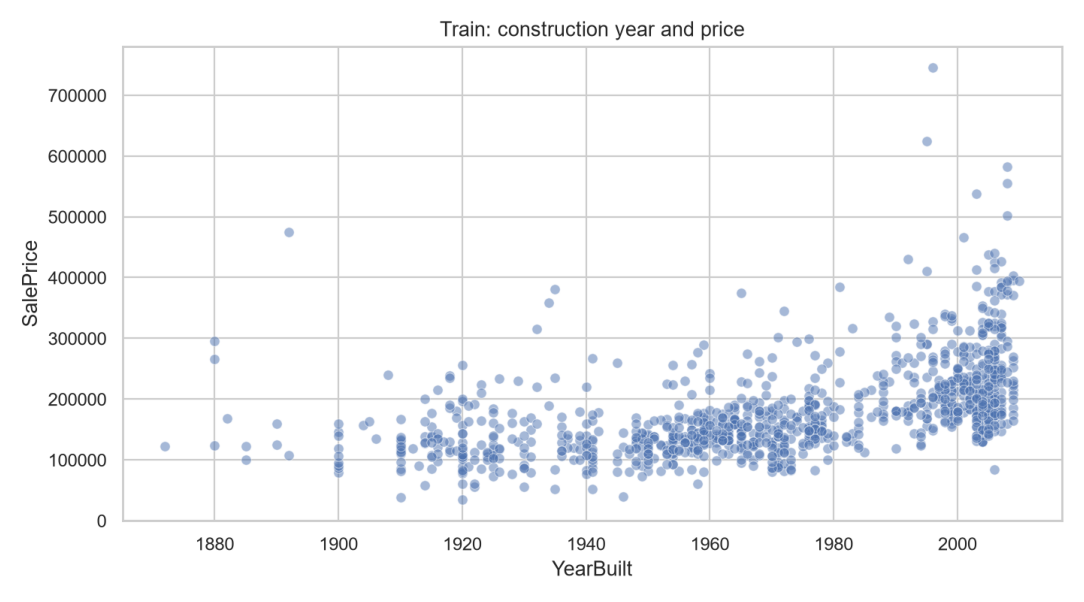

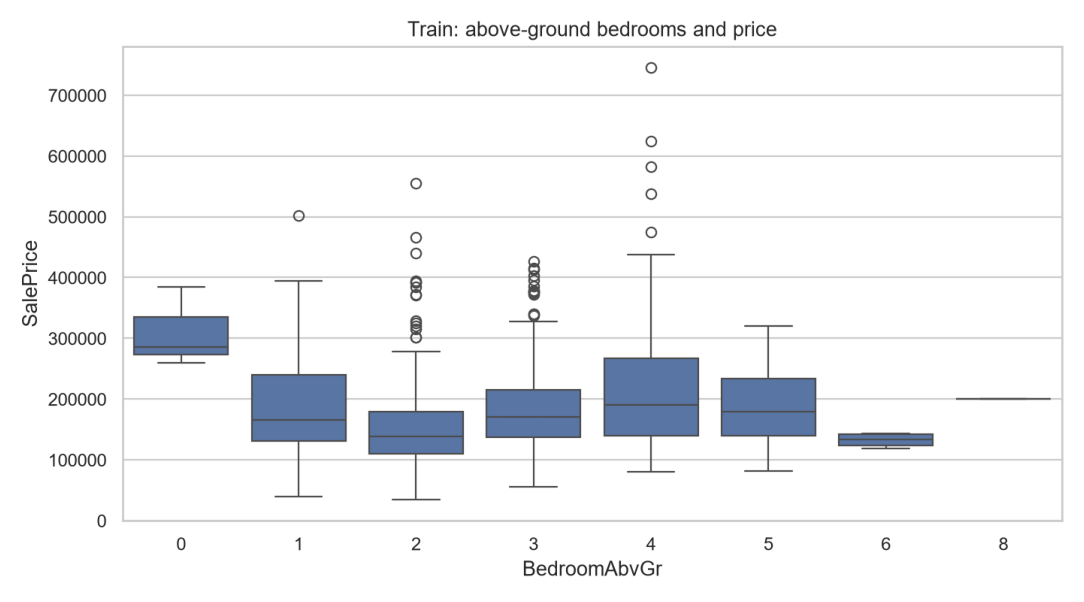

In [2]:
import matplotlib.pyplot as plt
for relative in summary['figures']:
    fig, ax = plt.subplots(figsize=(11, 7))
    ax.imshow(plt.imread(root / 'reports' / relative))
    ax.axis('off')
    plt.tight_layout()
    plt.show()

In [3]:
print((root / 'reports/eda_analysis.md').read_text(encoding='utf-8'))

# Phân tích EDA — chỉ Train

Phân tích 1022 mẫu Train; không đọc Validation hoặc Test để EDA.

## Xu hướng chính

SalePrice có skewness 1.762, trung vị 165,000 USD. Phân phối lệch phải: một số nhà giá cao kéo dài đuôi phân phối.
Diện tích sinh hoạt, chất lượng tổng thể và năm xây dựng có liên hệ với giá; biểu đồ cho thấy độ phân tán đáng kể giữa các căn nhà.

## Tương quan với giá

| Biến | Pearson r với SalePrice |
|---|---:|
| OverallQual | 0.7847 |
| GrLivArea | 0.6892 |
| GarageCars | 0.6427 |
| TotalBsmtSF | 0.5900 |
| FullBath | 0.5492 |
| YearBuilt | 0.5122 |
| BedroomAbvGr | 0.1599 |

Biến có tương quan tuyến tính dương lớn nhất trong 7 biến số là OverallQual (0.785).
Số phòng ngủ đơn lẻ không đại diện đầy đủ cho diện tích/chất lượng; không suy ra tăng phòng ngủ sẽ làm tăng giá tương ứng.

## Neighborhood

| Neighborhood | Trung vị USD | Số mẫu Train |
|---|---:|---:|
| MeadowV | 89,500 | 10 |
| BrDale | 103,000 | 12 |
| IDOTRR | 107,250 | 24 |
| BrkSide | 119,000 | 41 |
| OldT

Tổng quan bộ dữ liệu

In [4]:

import pandas as pd
import numpy as np
from IPython.display import display, Markdown

# Sử dụng biến root và data_guard đã khởi tạo ở cell trước
train_path = root / "data" / "processed" / "train.csv"

df = pd.read_csv(train_path)

required = ["SalePrice", "GrLivArea", "Neighborhood", "OverallQual"]
missing = set(required) - set(df.columns)

if missing:
    raise ValueError(f"Thiếu các cột: {missing}")

display(Markdown("## Tổng quan dữ liệu bất động sản"))

summary_table = pd.DataFrame({
    "Chỉ số": [
        "Số bất động sản",
        "Số thuộc tính",
        "Giá trung bình (USD)",
        "Giá trung vị (USD)",
        "Giá thấp nhất (USD)",
        "Giá cao nhất (USD)",
        "Diện tích trung bình (ft²)"
    ],
    "Giá trị": [
        len(df),
        len(df.columns),
        round(df["SalePrice"].mean(), 2),
        round(df["SalePrice"].median(), 2),
        df["SalePrice"].min(),
        df["SalePrice"].max(),
        round(df["GrLivArea"].mean(), 2)
    ]
})

display(summary_table)
display(df.head(10))


## Tổng quan dữ liệu bất động sản

,Chỉ số,Giá trị
0,Số bất động sản,1022.00
1,Số thuộc tính,81.00
2,Giá trung bình (USD),181312.69
3,Giá trung vị (USD),165000.00
4,Giá thấp nhất (USD),34900.00
5,Giá cao nhất (USD),745000.00
6,Diện tích trung bình (ft²),1529.24


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,136,20,RL,80.0,10400,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,5,2008,WD,Normal,174000
1,1453,180,RM,35.0,3675,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2006,WD,Normal,145000
2,763,60,FV,72.0,8640,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,6,2010,Con,Normal,215200
3,933,20,RL,84.0,11670,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,3,2007,WD,Normal,320000
4,436,60,RL,43.0,10667,Pave,NaN,IR2,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2009,ConLw,Normal,212000
5,630,80,RL,82.0,9020,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,GdPrv,NaN,0,6,2008,WD,Normal,168500
6,1211,60,RL,70.0,11218,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,GdPrv,Shed,400,5,2010,WD,Normal,189000
7,1119,80,RL,85.0,13825,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,140000
8,1085,60,RL,NaN,13031,Pave,NaN,IR2,Lvl,AllPub,...,0,NaN,NaN,NaN,0,7,2006,WD,Normal,187500
9,159,60,FV,100.0,12552,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,GdWo,NaN,0,5,2010,WD,Normal,254900


Biểu đồ phân bố giá nhà tương tác

In [5]:

import plotly.express as px

fig = px.histogram(
    df,
    x="SalePrice",
    nbins=50,
    marginal="box",
    title="Phân bố giá bán bất động sản",
    labels={
        "SalePrice": "Giá bán (USD)"
    }
)

median_price = df["SalePrice"].median()

fig.add_vline(
    x=median_price,
    line_dash="dash",
    annotation_text="Giá trung vị",
    annotation_position="top"
)

fig.update_layout(
    template="plotly_white",
    height=520,
    xaxis_title="Giá bán (USD)",
    yaxis_title="Số lượng nhà"
)

fig.show()


Quan hệ giữa diện tích và giá nhà

In [6]:

fig = px.scatter(
    df,
    x="GrLivArea",
    y="SalePrice",
    color="OverallQual",
    hover_data=[
        "Neighborhood",
        "BedroomAbvGr",
        "YearBuilt"
    ],
    title="Mối quan hệ giữa diện tích và giá bán",
    labels={
        "GrLivArea": "Diện tích (ft²)",
        "SalePrice": "Giá bán (USD)",
        "OverallQual": "Chất lượng nhà"
    },
    color_continuous_scale="Viridis"
)

fig.update_traces(
    marker=dict(size=8, opacity=0.65)
)

fig.update_layout(
    template="plotly_white",
    height=550
)

fig.show()

print(
    "Pearson correlation:",
    round(df["GrLivArea"].corr(df["SalePrice"]), 4)
)


Pearson correlation: 0.6892


So sánh giá nhà theo khu vực

In [7]:

neighborhood_stats = (
    df.groupby("Neighborhood")["SalePrice"]
    .agg(["median", "mean", "count"])
    .reset_index()
)

neighborhood_stats.columns = [
    "Neighborhood",
    "MedianPrice",
    "MeanPrice",
    "Count"
]

# Chỉ hiển thị các khu vực đủ số mẫu
neighborhood_stats = neighborhood_stats[
    neighborhood_stats["Count"] >= 10
]

top_areas = (
    neighborhood_stats
    .nlargest(15, "MedianPrice")
    .sort_values("MedianPrice")
)

fig = px.bar(
    top_areas,
    x="MedianPrice",
    y="Neighborhood",
    orientation="h",
    color="Count",
    hover_data=["MeanPrice", "Count"],
    title="15 khu vực có giá nhà trung vị cao nhất",
    labels={
        "MedianPrice": "Giá trung vị (USD)",
        "Neighborhood": "Khu vực",
        "Count": "Số căn nhà",
        "MeanPrice": "Giá trung bình (USD)"
    }
)

fig.update_layout(
    template="plotly_white",
    height=600
)

fig.show()


Giá nhà theo chất lượng xây dựng

In [8]:

fig = px.box(
    df,
    x="OverallQual",
    y="SalePrice",
    points="outliers",
    title="Ảnh hưởng của chất lượng xây dựng đến giá nhà",
    labels={
        "OverallQual": "Chất lượng xây dựng (1–10)",
        "SalePrice": "Giá bán (USD)"
    }
)

fig.update_layout(
    template="plotly_white",
    height=520
)

fig.show()


Correlation Heatmap

In [9]:

import seaborn as sns
import matplotlib.pyplot as plt

numeric_features = [
    "GrLivArea",
    "BedroomAbvGr",
    "FullBath",
    "GarageCars",
    "YearBuilt",
    "OverallQual",
    "TotalBsmtSF",
    "SalePrice"
]

correlation = df[numeric_features].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1, vmax=1,
    linewidths=0.5
)

plt.title(
    "Correlation Heatmap - House Price Dataset",
    fontsize=15
)

plt.tight_layout()
plt.show()

print("Tương quan các thuộc tính với SalePrice:")

display(
    correlation["SalePrice"]
    .drop("SalePrice")
    .sort_values(ascending=False)
    .to_frame("Pearson Correlation")
)


Tương quan các thuộc tính với SalePrice:


C:\Users\ASUS\AppData\Local\Temp\ipykernel_2052\2366211704.py:34: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


,Pearson Correlation
OverallQual,0.784720
GrLivArea,0.689238
GarageCars,0.642689
TotalBsmtSF,0.590017
FullBath,0.549164
YearBuilt,0.512206
BedroomAbvGr,0.159879


Bộ lọc dữ liệu tương tác

In [10]:

import ipywidgets as widgets
from IPython.display import display

areas = sorted(
    df["Neighborhood"].dropna().unique().tolist()
)

area_dropdown = widgets.Dropdown(
    options=["Tất cả"] + areas,
    value="Tất cả",
    description="Khu vực:"
)

quality_slider = widgets.IntRangeSlider(
    value=[1, 10],
    min=1,
    max=10,
    step=1,
    description="Chất lượng:"
)

def interactive_analysis(area, quality):
    filtered = df[
        df["OverallQual"].between(quality[0], quality[1])
    ].copy()

    if area != "Tất cả":
        filtered = filtered[
            filtered["Neighborhood"] == area
        ]

    if filtered.empty:
        print("Không có dữ liệu phù hợp.")
        return

    print("Số căn nhà:", len(filtered))
    print(
        "Giá trung vị:",
        f"${filtered['SalePrice'].median():,.0f}"
    )

    fig = px.scatter(
        filtered,
        x="GrLivArea",
        y="SalePrice",
        color="OverallQual",
        title="Phân tích bất động sản theo bộ lọc",
        labels={
            "GrLivArea": "Diện tích (ft²)",
            "SalePrice": "Giá bán (USD)"
        }
    )

    fig.update_layout(
        template="plotly_white",
        height=500
    )

    fig.show()

widgets.interact(
    interactive_analysis,
    area=area_dropdown,
    quality=quality_slider
)


interactive(children=(Dropdown(description='Khu vực:', options=('Tất cả', 'Blmngtn', 'Blueste', 'BrDale', 'Brk…

<function __main__.interactive_analysis(area, quality)>